# Bangla NewsLens — Beginner-Friendly Data Analysis and LSTM Model

**Project:** Bangla news classification into 7 categories  
**Dataset:** `nahid-hub/BLUGE-bengali-news-classification`  
**Model:** A simple PyTorch LSTM text classifier



## 2. Import libraries and set the category names

In [1]:
# 1. Import libraries
import os
import re
import json
import random
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# 1b. Shared text helpers used throughout the notebook
BANGLA_WORD_PATTERN = re.compile(r"[\u0980-\u09FF\u200c\u200d]+")

def tokenize(text):
    """Return Bangla-script word tokens using one shared rule."""
    return BANGLA_WORD_PATTERN.findall(str(text))

def normalize_text_for_match(text):
    """Normalize text for duplicate/overlap checks; this is not model preprocessing."""
    text = unicodedata.normalize("NFKC", str(text)).casefold()
    return re.sub(r"\s+", " ", text).strip()

# 2. Use the same random seed so results are more repeatable
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# 3. Label number -> news category name
LABEL_NAMES = {
    0: "Business",
    1: "Technology",
    2: "Crime",
    3: "Entertainment",
    4: "International Affairs",
    5: "Sports",
    6: "Lifestyle"
}
CATEGORIES = [LABEL_NAMES[i] for i in range(7)]

# 4. Use the GPU automatically when one is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device)
print("Number of categories:", len(CATEGORIES))
print(CATEGORIES)

PyTorch device: cuda
Number of categories: 7
['Business', 'Technology', 'Crime', 'Entertainment', 'International Affairs', 'Sports', 'Lifestyle']


## 3. Load the dataset

The dataset already provides official training, validation, and test splits. We keep those splits instead of randomly mixing all articles together.

In [2]:
# 1. Download the dataset
dataset_name = "nahid-hub/BLUGE-bengali-news-classification"
ds = load_dataset(dataset_name)

# 2. Check which splits are available
print("Available splits:", list(ds.keys()))

# 3. Convert each split to a pandas DataFrame
train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nDataset columns:", train_df.columns.tolist())

README.md:   0%|          | 0.00/3.23k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B / 80.3MB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 10.0MB            

validation.parquet: downloading bytes:           |  0.00B            

...

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/49840 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6230 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6230 [00:00<?, ? examples/s]

Available splits: ['train', 'validation', 'test']
Training rows: 49840
Validation rows: 6230
Test rows: 6230

Dataset columns: ['text', 'label']


## 4. Take a first look at the data

In [3]:
# 1. Display a few training articles
print(train_df.head(3))

# 2. See how the category numbers are distributed
print("\nLabel counts in the training split:")
print(train_df["label"].value_counts().sort_index())

# 3. Look at one complete example
sample_text = train_df.loc[0, "text"]
print("\nSample article (first 700 characters):")
print(sample_text[:700])
print("\nLabel number:", int(train_df.loc[0, "label"]))
print("Category:", LABEL_NAMES[int(train_df.loc[0, "label"])])

                                                text  label
0  পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনে...      0
1  টি কে গ্রুপের অন্যতম অঙ্গসংগঠন সুপার ফরমিকা অ্...      0
2  সপ্তাহের প্রথম কার্যদিবসেই নিম্নমুখী প্রবণতায় ...      0

Label counts in the training split:
label
0    7120
1    7120
2    7120
3    7120
4    7120
5    7120
6    7120
Name: count, dtype: int64

Sample article (first 700 characters):
পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনেক দিন পর্যন্ত সংরক্ষণ করা হয় ফ্রিজে রেখে। যার ঘরে ফ্রিজ আছে, তিনি আরেকটি ডিপ ফ্রিজের চাহিদা অনুভব করেন। আর যার নেই তিনি কোরবানির আগে ফ্রিজের দোকানে ছোটেন। এসব কারণেই গত এক মাসে ফ্রিজের চাহিদা বেড়েছে, বেড়েছে বেচাকেনাও।ফ্রিজের আমদানিকারক, দেশীয় প্রস্তুতকারক এবং বিক্রেতাদের সঙ্গে কথা বলে জানা গেছে, এবার ফ্রিজের বিক্রি ভালো। বরাবরের মতোই বেশি বিক্রি হচ্ছে ডিপ ফ্রিজ।সংশ্লিষ্ট ব্যবসায়ীরা বলছেন, সারা বছর দেশে প্রায় ১১ লাখ ফ্রিজ বিক্রি হয়। এর প্রায় ৩০ শতাংশই বিক্রি হয় কোরবানির ঈদের আগে। অর্থাৎ কোরবানি সামনে রেখে তিন লাখের মতো ফ্র

## 5. Clean the data without making the code complicated

We apply a few clear rules:
1. Remove rows with missing or blank article text.
2. Remove exact duplicate articles inside each split.
3. Remove an article from validation or test if the same text is already in an earlier split.
4. Remove identical text that has conflicting labels.

We do not use complicated near-duplicate rules in this beginner version. We print the row counts so the cleaning is visible.

In [4]:
# 1. Save the original row counts for comparison
original_counts = {
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df)
}

# 2. Clean one official split without changing the downloaded dataset
def clean_split(dataframe):
    cleaned = dataframe[["text", "label"]].copy()
    cleaned = cleaned.dropna(subset=["text", "label"])
    cleaned["text"] = cleaned["text"].astype(str).str.strip()
    cleaned = cleaned[cleaned["text"] != ""]
    cleaned["label"] = cleaned["label"].astype(int)

    # Treat text that differs only by Unicode form/whitespace/case as a duplicate.
    cleaned["_normalized_text"] = cleaned["text"].map(normalize_text_for_match)
    cleaned = cleaned.drop_duplicates(subset=["_normalized_text", "label"])
    return cleaned.drop(columns=["_normalized_text"]).reset_index(drop=True)

train_df = clean_split(train_df)
val_df = clean_split(val_df)
test_df = clean_split(test_df)

# 3. Find normalized article texts assigned conflicting labels anywhere in the splits
all_for_check = pd.concat([train_df, val_df, test_df], ignore_index=True)
all_for_check["_normalized_text"] = all_for_check["text"].map(normalize_text_for_match)
label_counts_per_text = all_for_check.groupby("_normalized_text")["label"].nunique()
conflicting_texts = set(label_counts_per_text[label_counts_per_text > 1].index)

def without_conflicting_texts(dataframe):
    normalized = dataframe["text"].map(normalize_text_for_match)
    return dataframe.loc[~normalized.isin(conflicting_texts)].copy()

train_df = without_conflicting_texts(train_df)
val_df = without_conflicting_texts(val_df)
test_df = without_conflicting_texts(test_df)

# 4. Remove normalized validation/test duplicates seen in earlier splits
train_texts = set(train_df["text"].map(normalize_text_for_match))
val_texts_normalized = val_df["text"].map(normalize_text_for_match)
val_df = val_df.loc[~val_texts_normalized.isin(train_texts)].copy()

texts_seen_earlier = train_texts | set(val_df["text"].map(normalize_text_for_match))
test_texts_normalized = test_df["text"].map(normalize_text_for_match)
test_df = test_df.loc[~test_texts_normalized.isin(texts_seen_earlier)].copy()

# 5. Reset row indexes after removing rows
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 6. Add readable category names
train_df["category"] = train_df["label"].map(LABEL_NAMES)
val_df["category"] = val_df["label"].map(LABEL_NAMES)
test_df["category"] = test_df["label"].map(LABEL_NAMES)

# 7. Print the effect of cleaning
clean_counts = {
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df)
}
print("Rows before cleaning:", original_counts)
print("Rows after cleaning: ", clean_counts)
print("Rows removed:         ", {split: original_counts[split] - clean_counts[split] for split in original_counts})

# 8. Safety checks using normalized text, not just exact raw strings
train_texts = set(train_df["text"].map(normalize_text_for_match))
val_texts = set(val_df["text"].map(normalize_text_for_match))
test_texts = set(test_df["text"].map(normalize_text_for_match))
print("\nNo normalized train/validation overlap:", len(train_texts & val_texts) == 0)
print("No normalized train/test overlap:       ", len(train_texts & test_texts) == 0)
print("No normalized validation/test overlap:  ", len(val_texts & test_texts) == 0)

print("\nTraining sample after cleaning:")
print(train_df[["category", "text"]].head(2))


Rows before cleaning: {'train': 49840, 'validation': 6230, 'test': 6230}
Rows after cleaning:  {'train': 49481, 'validation': 6158, 'test': 6135}
Rows removed:          {'train': 359, 'validation': 72, 'test': 95}

No normalized train/validation overlap: True
No normalized train/test overlap:        True
No normalized validation/test overlap:   True

Training sample after cleaning:
   category                                               text
0  Business  পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনে...
1  Business  টি কে গ্রুপের অন্যতম অঙ্গসংগঠন সুপার ফরমিকা অ্...


## 6. EDA questions we will investigate

The assignment asks for 10–15 questions. We will answer these using counts, tables, and charts:

1. How many articles remain in each split after cleaning?
2. How many articles are in each category?
3. Are the seven categories roughly balanced?
4. Which split contains the most articles?
5. How long are the articles, measured in Bangla words?
6. Which category has the highest median article length?
7. Do article lengths vary a lot within each category?
8. Which words appear most often in the training split?
9. Which words appear most often in each category?
10. Are there missing or blank texts after cleaning?
11. Did the cleaning process leave exact text overlap between splits?
12. Are category counts similar across the three splits?
13. What does a very short or very long article look like?
14. Which categories does the final model confuse most often? (We answer this in the model evaluation section.)

## 7. Add simple features for EDA

In [5]:
# 1. Combine the cleaned splits for data analysis only
train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"
clean_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# 2. Count tokens with the same tokenizer that the model will use
def count_bangla_words(text):
    return len(tokenize(text))

# 3. Create article length columns
clean_df["character_count"] = clean_df["text"].str.len()
clean_df["word_count"] = clean_df["text"].apply(count_bangla_words)

# 4. Check for missing values and blank text
print("Rows in cleaned data:", len(clean_df))
print("Missing text values:", clean_df["text"].isna().sum())
print("Blank text rows:", (clean_df["text"].str.strip() == "").sum())
print("\nArticle length summary (Bangla words):")
print(clean_df["word_count"].describe().round(1))

Rows in cleaned data: 61774
Missing text values: 0
Blank text rows: 0

Article length summary (Bangla words):
count    61774.0
mean       254.8
std        173.9
min         10.0
25%        136.0
50%        234.0
75%        311.0
max       5372.0
Name: word_count, dtype: float64


## 8. Chart 1 — All seven categories are represented

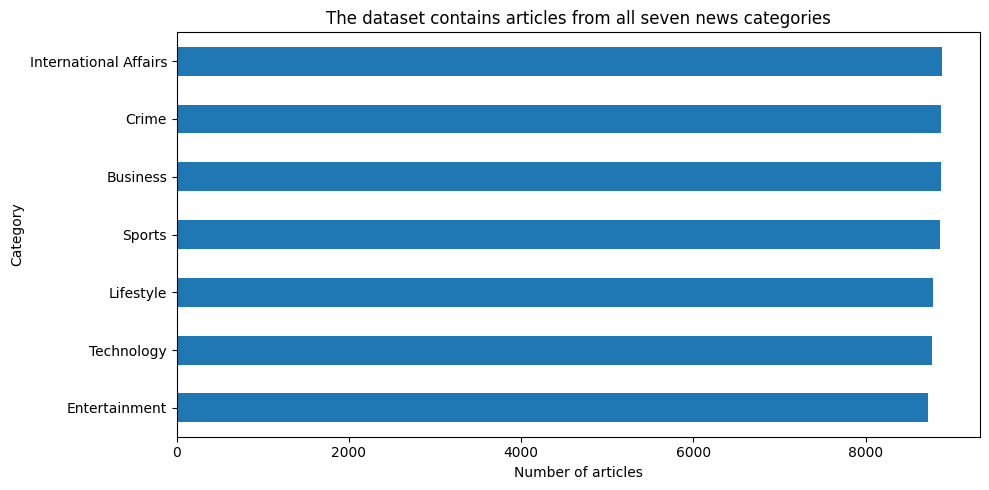

category
International Affairs    8885
Crime                    8878
Business                 8872
Sports                   8866
Lifestyle                8781
Technology               8769
Entertainment            8723
Name: count, dtype: int64


In [6]:
# Count how many articles belong to each category
category_counts = clean_df["category"].value_counts().reindex(CATEGORIES, fill_value=0)

plt.figure(figsize=(10, 5))
category_counts.sort_values().plot(kind="barh")
plt.title("The dataset contains articles from all seven news categories")
plt.xlabel("Number of articles")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print(category_counts.sort_values(ascending=False))

**Interpretation:** The bars show the number of articles in each category. Similar bar lengths mean the classes are more balanced, while a much smaller class may be harder for a model to learn. Use the displayed counts to describe the actual balance in your report.

## 9. Chart 2 — The official training split contains most articles

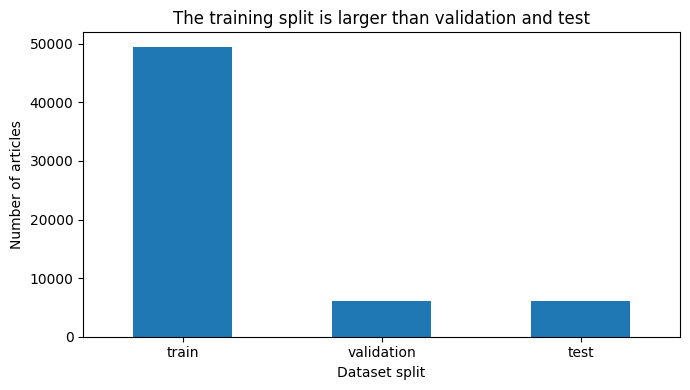

split
train         49481
validation     6158
test           6135
Name: count, dtype: int64


In [7]:
# Count rows in each official split
split_counts = clean_df["split"].value_counts().reindex(["train", "validation", "test"])

plt.figure(figsize=(7, 4))
split_counts.plot(kind="bar")
plt.title("The training split is larger than validation and test")
plt.xlabel("Dataset split")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(split_counts)

**Interpretation:** The training data teaches the model. Validation data helps us check progress during training, while the held-out test data is reserved for the final evaluation. Keeping the test split separate gives us a fairer estimate of performance on unseen articles.

## 10. Chart 3 — Article length has a wide range

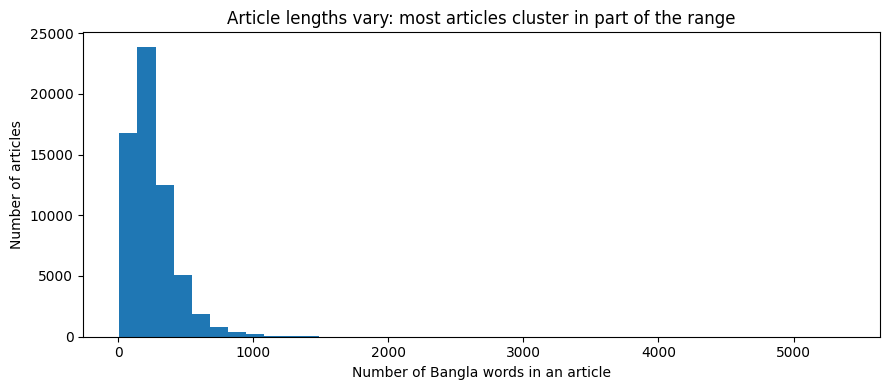

Shortest article words: 10
Median article words:   234.0
Longest article words:  5372


In [8]:
plt.figure(figsize=(9, 4))
plt.hist(clean_df["word_count"], bins=40)
plt.title("Article lengths vary: most articles cluster in part of the range")
plt.xlabel("Number of Bangla words in an article")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()

print("Shortest article words:", clean_df["word_count"].min())
print("Median article words:  ", clean_df["word_count"].median())
print("Longest article words: ", clean_df["word_count"].max())

**Interpretation:** The histogram shows whether article lengths are concentrated in a small range or spread widely. Very short texts may contain too little context, while very long texts take more computation and may be truncated before the model reads them.

## 11. Chart 4 — Typical article length differs by category

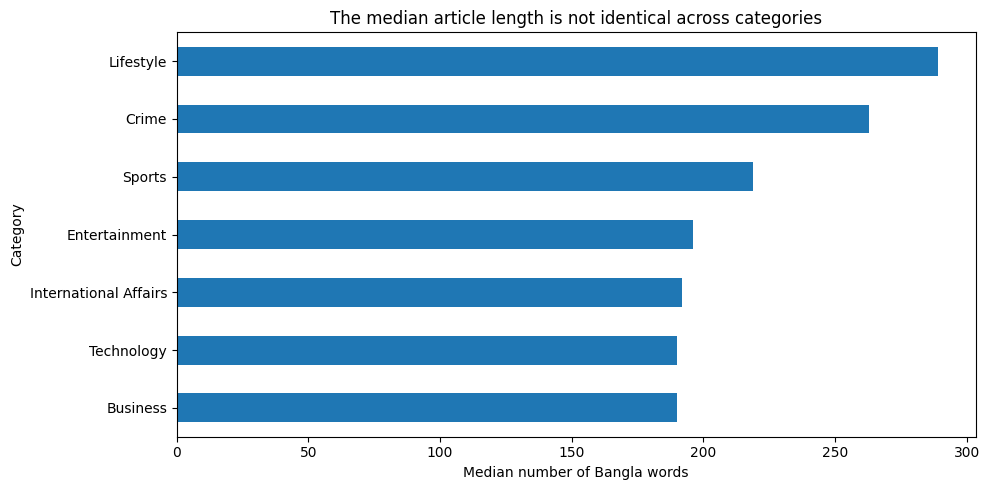

category
Lifestyle                289.0
Crime                    263.0
Sports                   219.0
Entertainment            196.0
International Affairs    192.0
Technology               190.0
Business                 190.0
Name: word_count, dtype: float64


In [9]:
median_words = clean_df.groupby("category")["word_count"].median().reindex(CATEGORIES)

plt.figure(figsize=(10, 5))
median_words.sort_values().plot(kind="barh")
plt.title("The median article length is not identical across categories")
plt.xlabel("Median number of Bangla words")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print(median_words.sort_values(ascending=False).round(1))

**Interpretation:** The median is the middle article length and is less affected by a few very long articles than the mean. Differences may reflect how news is written in different sections. Do not assume one category is always longer; use your chart and table to identify the actual result.

## 12. Chart 5 — Interactive article-length chart (choose a category)

Use the dropdown on the chart to select a category. This is an interactive notebook chart; the Django website should later serve chart data from its own views/database as required by the assignment.

In [10]:
# Create one histogram for each category.
# The dropdown makes only the selected category visible.
fig = go.Figure()

for category in CATEGORIES:
    category_words = clean_df.loc[clean_df["category"] == category, "word_count"]
    fig.add_trace(go.Histogram(x=category_words, name=category, visible=(category == CATEGORIES[0]), nbinsx=35))

buttons = []
for selected_index, category in enumerate(CATEGORIES):
    visible_values = [i == selected_index for i in range(len(CATEGORIES))]
    buttons.append({
        "label": category,
        "method": "update",
        "args": [
            {"visible": visible_values},
            {"title": f"Article-length distribution — {category}"}
        ]
    })

fig.update_layout(
    title=f"Article-length distribution — {CATEGORIES[0]}",
    xaxis_title="Number of Bangla words",
    yaxis_title="Number of articles",
    updatemenus=[{"buttons": buttons, "direction": "down", "x": 1.02, "y": 1.15}],
    width=900,
    height=500
)
fig.show()

**Interpretation:** Change the category in the dropdown and compare the shape of each distribution. A wider distribution means the category contains articles with more varied lengths. This chart also helps us choose a reasonable maximum sequence length for the model.

## 13. Chart 6 — The most common Bangla words in training articles

In [31]:
# Count words in TRAINING articles only.
# We use training text for word-frequency analysis to keep the modeling workflow clear.


word_counts = Counter()

for text in train_df["text"]:
    word_counts.update(tokenize(text))

top_words = word_counts.most_common(15)
top_words_df = pd.DataFrame(top_words, columns=["word", "count"])

fig = go.Figure(go.Bar(
    x=top_words_df["count"][::-1],
    y=top_words_df["word"][::-1],
    orientation="h"
))
fig.update_layout(
    title="A small number of words appear very frequently in the training data",
    xaxis_title="Word frequency",
    yaxis_title="Bangla word",
    height=500
)
fig.show()

print(top_words_df)

     word   count
0       ও  134596
1     করে   95914
2       এ   91128
3    থেকে   82108
4      না   80208
5      এই   72468
6     করা   61810
7     হবে   54684
8      হয়   54501
9    জন্য   51868
10  সঙ্গে   47817
11   বলেন   46963
12   তিনি   45485
13     এক   44513
14   তাঁর   43362


**Interpretation:** Frequently used words can include general words that appear across many topics, not only words that identify a category. A word being frequent does not automatically make it useful for classification. The model needs to learn patterns of words in context.

## 14. Chart 7 — Interactive top words by category

In [28]:
# Count word frequency in each category using TRAINING articles only.
category_word_counts = {}

for category in CATEGORIES:
    category_texts = train_df.loc[train_df["category"] == category, "text"]
    counts = Counter()
    for text in category_texts:
        counts.update(tokenize(text))
    category_word_counts[category] = counts

# Add one bar chart trace for each category.
fig = go.Figure()
for category in CATEGORIES:
    words = category_word_counts[category].most_common(10)
    word_names = [item[0] for item in words]
    word_frequencies = [item[1] for item in words]
    fig.add_trace(go.Bar(x=word_names, y=word_frequencies, name=category, visible=(category == CATEGORIES[0])))

buttons = []
for selected_index, category in enumerate(CATEGORIES):
    visible_values = [i == selected_index for i in range(len(CATEGORIES))]
    buttons.append({
        "label": category,
        "method": "update",
        "args": [
            {"visible": visible_values},
            {"title": f"Ten most frequent words — {category}"}
        ]
    })

fig.update_layout(
    title=f"Ten most frequent words — {CATEGORIES[0]}",
    xaxis_title="Word",
    yaxis_title="Frequency in training articles",
    updatemenus=[{"buttons": buttons, "direction": "down", "x": 1.02, "y": 1.15}],
    width=950,
    height=500
)
fig.show()

**Interpretation:** Select different categories to see which words are frequent in each group. Frequent words are only clues, not proof that a word uniquely belongs to a category. This chart is useful for exploring the data, and the LSTM will learn word patterns from labeled examples.

## 15. Check category counts across the three splits

category    Business  Technology  Crime  Entertainment  International Affairs  \
split                                                                           
train           7101        7020   7103           7006                   7111   
validation       886         876    888            864                    886   
test             885         873    887            853                    888   

category    Sports  Lifestyle  
split                          
train         7102       7038  
validation     882        876  
test           882        867  


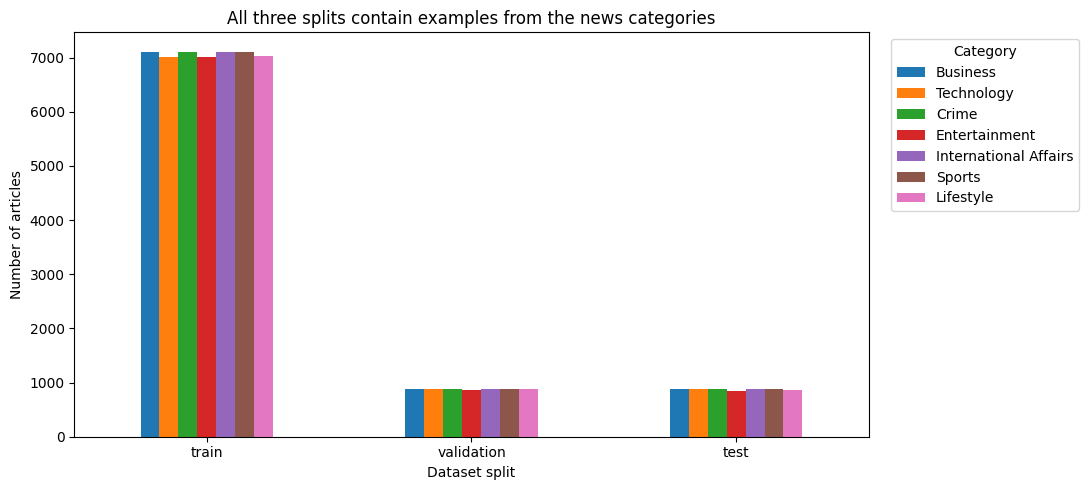


Two shortest articles:
Category: Technology | Words: 10
পড়াশোনা সংক্রান্ত সর্বশেষ তথ্যপেতে ভিজিট কর, লাইক দাও, মতামত জানাও 

Category: Technology | Words: 10
পানচিনি পান চিনি নাগায়েহলুদ মনেহলুদবিয়ের গাড়ি তালাকের গাড়িবাসররাত বাসরদিনবউভাত জামাইভাত 

Two longest articles:
Category: Entertainment | Words: 5372
বাংলাদেশ টেলিভিশনআনন্দমেলাঈদের দিন বিটিভিতে রাত ১০টার ইংরেজি সংবাদের পর দেখানো হবে ম্যাগাজিন অনুষ্ঠান আনন্দমেলা । তারকায় ভরা জমজমাট এ আয়োজনটি এবার উপস্থাপনা করছেন সজল ও নাবিলা। অনুষ্ঠান প্রযোজনা ও পরিচালনা করেছেন নূর আনোয়ার ও মাহফুজার রহমান।এবারের আন 

Category: Lifestyle | Words: 3088
১৯৭৫ সালের ১৫ আগস্ট জাতির জনক বঙ্গবন্ধু শেখ মুজিবুর রহমানকে সপরিবার নৃশংসভাবে হত্যা করা হয়। বঙ্গবন্ধুর খুনিদের রেহাই দেওয়ার জন্য দায়মুক্তি (ইনডেমনিটি) অধ্যাদেশ জারি করে খন্দকার মোশতাক সরকার। এই ঘটনার ২১ বছর পর ১৯৯৬ সালে আওয়ামী লীগ সরকার সেই দায়মুক্তি 



In [13]:
# This table helps check that no category is missing from a split.
split_category_counts = pd.crosstab(clean_df["split"], clean_df["category"]).reindex(
    index=["train", "validation", "test"], columns=CATEGORIES, fill_value=0
)
print(split_category_counts)

# Chart 8: category counts by split
split_category_counts.plot(kind="bar", figsize=(11, 5))
plt.title("All three splits contain examples from the news categories")
plt.xlabel("Dataset split")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Show examples of very short and very long articles
print("\nTwo shortest articles:")
for _, row in clean_df.nsmallest(2, "word_count").iterrows():
    print("Category:", row["category"], "| Words:", row["word_count"])
    print(row["text"][:250], "\n")

print("Two longest articles:")
for _, row in clean_df.nlargest(2, "word_count").iterrows():
    print("Category:", row["category"], "| Words:", row["word_count"])
    print(row["text"][:250], "\n")

**Interpretation:** The table and chart help compare the category distribution in train, validation, and test. The short and long article previews make the length statistics easier to understand. The plots in this notebook are for analysis; the final Django Data Story pages must implement the required interactive charts using data served by Django views or the database.

## 16. Prepare text for the LSTM model


A neural network needs numbers, not raw strings. We will:
1. Split each Bangla article into words using one shared tokenizer.
2. Build a vocabulary from **training text only**.
3. Give the 30,000 most common words integer IDs. Every other word becomes the unknown word.
4. Use `0` for padding and `1` for unknown words.
5. Keep at most 300 words per article so each input has the same length.
6. **Right-pad** shorter articles and save each article's real token length. The LSTM will use packed sequences so padding steps are not processed as real words.

This is a simple word-level approach; it is not a pretrained language model. The held-out test set should be used for final evaluation, not to choose modeling settings.


In [14]:
# 1. Keep the vocabulary small enough for a student project
MAX_VOCAB_SIZE = 30000
MAX_LEN = 300
PAD_ID = 0
UNKNOWN_ID = 1

# 2. Count words using TRAINING articles only
training_word_counts = Counter()
for text in train_df["text"]:
    training_word_counts.update(tokenize(text))

# 3. Give each word a number
vocab = {"<PAD>": PAD_ID, "<UNK>": UNKNOWN_ID}
for word, count in training_word_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Example vocabulary entries:", list(vocab.items())[:10])

# 4. Convert one article to IDs and record how many real tokens it contains
def encode_text_with_length(text):
    words = tokenize(text)[:MAX_LEN]
    word_ids = [vocab.get(word, UNKNOWN_ID) for word in words]

    # Packed LSTMs need a sequence length of at least 1.
    # If tokenization finds no Bangla words, represent the text as one unknown token.
    if not word_ids:
        word_ids = [UNKNOWN_ID]

    sequence_length = len(word_ids)

    # RIGHT-pad: real tokens come first, padding comes after them.
    word_ids = word_ids + [PAD_ID] * (MAX_LEN - sequence_length)
    return word_ids, sequence_length

def encode_text(text):
    """Return the fixed-length token-ID row used by prediction."""
    return encode_text_with_length(text)[0]

# Encode a collection efficiently without retaining a large Python list of all IDs.
def encode_texts(texts):
    encoded_ids = np.full((len(texts), MAX_LEN), PAD_ID, dtype=np.int64)
    sequence_lengths = np.empty(len(texts), dtype=np.int64)

    for row_index, text in enumerate(texts):
        word_ids, sequence_length = encode_text_with_length(text)
        encoded_ids[row_index] = word_ids
        sequence_lengths[row_index] = sequence_length

    return torch.from_numpy(encoded_ids), torch.from_numpy(sequence_lengths)

# Try the conversion on one article
example_ids, example_length = encode_text_with_length(train_df.loc[0, "text"])
print("Number of token IDs:", len(example_ids))
print("Number of real tokens:", example_length)
print("First 25 IDs:", example_ids[:25])
print("Last 10 IDs (usually padding for shorter articles):", example_ids[-10:])


Vocabulary size: 30000
Example vocabulary entries: [('<PAD>', 0), ('<UNK>', 1), ('ও', 2), ('করে', 3), ('এ', 4), ('থেকে', 5), ('না', 6), ('এই', 7), ('করা', 8), ('হবে', 9)]
Number of token IDs: 300
Number of real tokens: 300
First 25 IDs: [3747, 3889, 18381, 1, 77, 9161, 1269, 66, 64, 81, 1918, 8, 10, 6468, 433, 836, 734, 8201, 50, 14, 894, 10152, 12997, 1192, 2706]
Last 10 IDs (usually padding for shorter articles): [2395, 33, 1392, 13, 528, 72, 8201, 350, 10, 15]


## 17. Convert train, validation, and test text into tensors

In [15]:
# 1. Convert article text to integer sequences and keep each true length
X_train, train_lengths = encode_texts(train_df["text"].tolist())
X_val, val_lengths = encode_texts(val_df["text"].tolist())
X_test, test_lengths = encode_texts(test_df["text"].tolist())

# 2. Convert category labels to tensors
y_train = torch.tensor(train_df["label"].to_numpy(), dtype=torch.long)
y_val = torch.tensor(val_df["label"].to_numpy(), dtype=torch.long)
y_test = torch.tensor(test_df["label"].to_numpy(), dtype=torch.long)

print("Training tensor shape:", X_train.shape, "| lengths:", train_lengths.shape)
print("Validation tensor shape:", X_val.shape, "| lengths:", val_lengths.shape)
print("Test tensor shape:", X_test.shape, "| lengths:", test_lengths.shape)

# 3. Group token IDs, true sequence lengths, and labels into batches
BATCH_SIZE = 64
train_dataset = TensorDataset(X_train, train_lengths, y_train)
val_dataset = TensorDataset(X_val, val_lengths, y_val)
test_dataset = TensorDataset(X_test, test_lengths, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Number of training batches:", len(train_loader))


Training tensor shape: torch.Size([49481, 300]) | lengths: torch.Size([49481])
Validation tensor shape: torch.Size([6158, 300]) | lengths: torch.Size([6158])
Test tensor shape: torch.Size([6135, 300]) | lengths: torch.Size([6135])
Number of training batches: 774


## 18. Build a simple LSTM model


The model has these parts:
- **Embedding:** converts each word ID into a vector of numbers.
- **Packed LSTM:** processes only each article's real tokens using its saved sequence length. This prevents right-padding tokens from changing the valid hidden states.
- **Bidirectional LSTM:** in the improved model, reads each article forwards and backwards.
- **Max-pooling:** keeps the strongest signal across real word positions and masks padded output positions.
- **Dropout:** randomly switches off some values during training, which helps reduce overfitting.
- **Linear layer:** produces one score for each of the seven categories.

Setting `IMPROVED = False` in the code cell builds the simpler one-direction LSTM and uses its final hidden state. Both versions use packed sequences so padding is handled consistently.


In [16]:
# 18. Build the LSTM model
IMPROVED = True          # True = bidirectional LSTM + max-pooling; False = one-directional LSTM

class NewsLSTM(nn.Module):
    def __init__(self, vocabulary_size, embedding_size, hidden_size, number_of_classes, improved=True):
        super().__init__()
        self.improved = improved
        self.embedding = nn.Embedding(vocabulary_size, embedding_size, padding_idx=PAD_ID)
        self.embed_dropout = nn.Dropout(0.2 if improved else 0.0)
        self.lstm = nn.LSTM(
            embedding_size,
            hidden_size,
            batch_first=True,
            bidirectional=improved
        )
        self.dropout = nn.Dropout(0.4 if improved else 0.3)
        output_input_size = hidden_size * 2 if improved else hidden_size
        self.output_layer = nn.Linear(output_input_size, number_of_classes)

    def forward(self, input_ids, lengths=None):
        # Lengths count real tokens, not padding. Training/prediction passes them explicitly.
        if lengths is None:
            lengths = (input_ids != PAD_ID).sum(dim=1).clamp(min=1)

        lengths_cpu = lengths.detach().to(device="cpu", dtype=torch.long)
        word_vectors = self.embed_dropout(self.embedding(input_ids))

        # The LSTM skips padded positions instead of processing them as real words.
        packed_vectors = pack_padded_sequence(
            word_vectors, lengths_cpu, batch_first=True, enforce_sorted=False
        )
        packed_outputs, (last_hidden_state, _) = self.lstm(packed_vectors)

        if self.improved:
            all_outputs, _ = pad_packed_sequence(
                packed_outputs, batch_first=True, total_length=input_ids.size(1)
            )
            positions = torch.arange(input_ids.size(1), device=input_ids.device).unsqueeze(0)
            real_word = positions < lengths.to(input_ids.device).unsqueeze(1)
            all_outputs = all_outputs.masked_fill(~real_word.unsqueeze(-1), -1e9)
            final_output = all_outputs.max(dim=1).values
        else:
            # Packed sequences make this the final real token, not the padded last slot.
            final_output = last_hidden_state[-1]

        final_output = self.dropout(final_output)
        return self.output_layer(final_output)

EMBEDDING_SIZE = 128 if IMPROVED else 64
HIDDEN_SIZE = 128 if IMPROVED else 64

torch.manual_seed(RANDOM_STATE)       # same starting weights every time you re-run this cell
model = NewsLSTM(
    vocabulary_size=len(vocab),
    embedding_size=EMBEDDING_SIZE,
    hidden_size=HIDDEN_SIZE,
    number_of_classes=len(CATEGORIES),
    improved=IMPROVED
).to(device)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


NewsLSTM(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (embed_dropout): Dropout(p=0.2, inplace=False)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (output_layer): Linear(in_features=256, out_features=7, bias=True)
)
Trainable parameters: 4105991


## 19. Train the model and check validation performance


We train for up to 12 epochs. An epoch means the model has gone through the full training split once. Training stops early if validation accuracy does not improve for 2 epochs, and the weights from the best epoch are kept. Gradient clipping keeps the updates stable. If you run this on CPU, training may be slow; a Colab GPU is recommended.

In [17]:
# 19. Train the model, keep the best epoch, and record the history
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
EPOCHS = 12
PATIENCE = 2          # stop if validation accuracy does not improve for 2 epochs

def evaluate_model(model, data_loader):
    model.eval()
    total_loss = 0.0
    all_true = []
    all_predicted = []
    with torch.no_grad():
        for batch_text, batch_lengths, batch_labels in data_loader:
            batch_text = batch_text.to(device)
            batch_lengths = batch_lengths.to(device)
            batch_labels = batch_labels.to(device)
            scores = model(batch_text, batch_lengths)
            loss = loss_function(scores, batch_labels)
            total_loss += loss.item()
            predictions = torch.argmax(scores, dim=1)
            all_true.extend(batch_labels.cpu().tolist())
            all_predicted.extend(predictions.cpu().tolist())
    average_loss = total_loss / max(1, len(data_loader))
    accuracy = accuracy_score(all_true, all_predicted)
    return average_loss, accuracy, all_true, all_predicted

# Lists that the Section 20 charts read
train_losses, validation_losses, validation_accuracies = [], [], []
best_val_acc, best_state, best_epoch, bad_epochs = 0.0, None, 0, 0

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0
    for batch_text, batch_lengths, batch_labels in train_loader:
        batch_text = batch_text.to(device)
        batch_lengths = batch_lengths.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        loss = loss_function(model(batch_text, batch_lengths), batch_labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # prevents unstable updates
        optimizer.step()
        total_train_loss += loss.item()

    average_train_loss = total_train_loss / max(1, len(train_loader))
    val_loss, val_accuracy, _, _ = evaluate_model(model, val_loader)
    train_losses.append(average_train_loss)
    validation_losses.append(val_loss)
    validation_accuracies.append(val_accuracy)
    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {average_train_loss:.4f} | "
          f"val loss {val_loss:.4f} | val acc {val_accuracy:.4f}")

    if val_accuracy > best_val_acc:          # remember the best epoch
        best_val_acc = val_accuracy
        best_epoch = epoch + 1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Stopping early: no improvement for", PATIENCE, "epochs.")
            break

if best_state is None:
    raise RuntimeError("Training did not save a best checkpoint. Check the training data and validation loop.")
model.load_state_dict(best_state)            # use the best epoch, not the last one
print(f"\nBest validation accuracy: {best_val_acc:.4f} at epoch {best_epoch} (this epoch's weights are loaded)")


Epoch 1/12 | train loss 0.9686 | val loss 0.3950 | val acc 0.8698
Epoch 2/12 | train loss 0.3800 | val loss 0.2808 | val acc 0.9053
Epoch 3/12 | train loss 0.2779 | val loss 0.2611 | val acc 0.9165
Epoch 4/12 | train loss 0.2210 | val loss 0.2427 | val acc 0.9237
Epoch 5/12 | train loss 0.1780 | val loss 0.2434 | val acc 0.9256
Epoch 6/12 | train loss 0.1418 | val loss 0.2682 | val acc 0.9211
Epoch 7/12 | train loss 0.1149 | val loss 0.2788 | val acc 0.9186
Stopping early: no improvement for 2 epochs.

Best validation accuracy: 0.9256 at epoch 5 (this epoch's weights are loaded)


## 20. Chart 8 — Training and validation curves

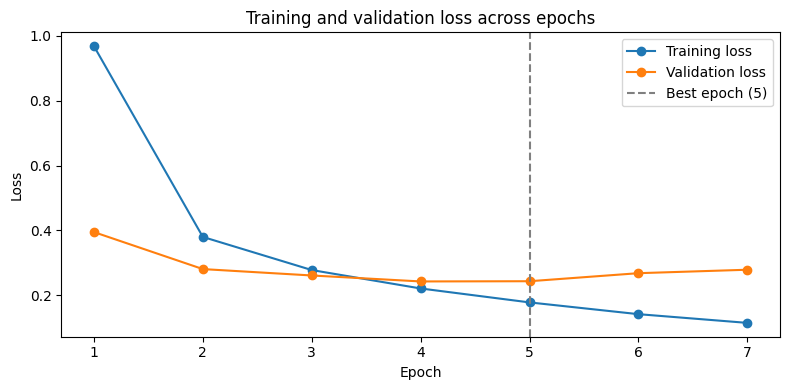

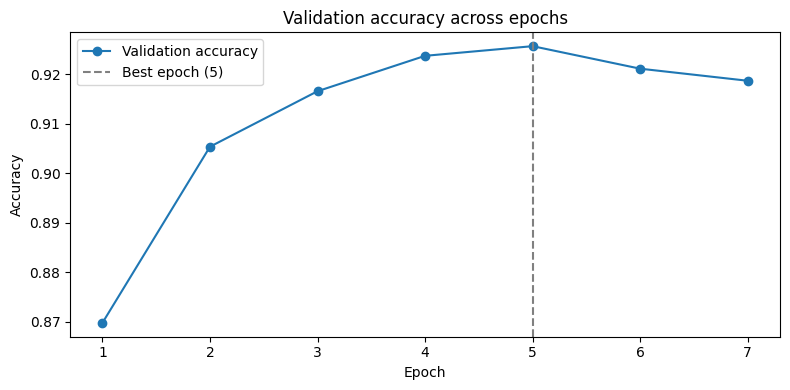

Epochs run: 7
Best validation accuracy: 0.9256 at epoch 5


In [18]:
# 20. Chart 8: training and validation curves
epochs_run = range(1, len(train_losses) + 1)      # matches however many epochs actually ran

# Loss curves
plt.figure(figsize=(8, 4))
plt.plot(epochs_run, train_losses, marker="o", label="Training loss")
plt.plot(epochs_run, validation_losses, marker="o", label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.title("Training and validation loss across epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# Accuracy curve
plt.figure(figsize=(8, 4))
plt.plot(epochs_run, validation_accuracies, marker="o", label="Validation accuracy")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.title("Validation accuracy across epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

print("Epochs run:", len(train_losses))
print("Best validation accuracy:", round(best_val_acc, 4), "at epoch", best_epoch)


**Interpretation:** Training loss usually decreases as the model learns. If training loss keeps decreasing while validation loss increases, the model may be overfitting. Record what your curves actually show; do not claim that training is successful based only on training loss.

## 21. Final evaluation on the held-out test split

The test split is used only after training. These are the final metrics for this run; they are not copied from the earlier Claude notebook.

In [19]:
# 1. Evaluate once on test data
test_loss, test_accuracy, test_true, test_predicted = evaluate_model(model, test_loader)
test_macro_f1 = f1_score(test_true, test_predicted, average="macro")
test_weighted_f1 = f1_score(test_true, test_predicted, average="weighted")

print(f"Test loss:       {test_loss:.4f}")
print(f"Test accuracy:   {test_accuracy:.4f}")
print(f"Test macro F1:   {test_macro_f1:.4f}")
print(f"Test weighted F1:{test_weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    test_true,
    test_predicted,
    labels=list(range(len(CATEGORIES))),
    target_names=CATEGORIES,
    zero_division=0
))


Test loss:       0.2317
Test accuracy:   0.9255
Test macro F1:   0.9252
Test weighted F1:0.9254

Classification report:
                       precision    recall  f1-score   support

             Business       0.94      0.95      0.95       885
           Technology       0.90      0.84      0.87       873
                Crime       0.98      0.98      0.98       887
        Entertainment       0.94      0.95      0.95       853
International Affairs       0.90      0.92      0.91       888
               Sports       0.97      0.98      0.97       882
            Lifestyle       0.84      0.86      0.85       867

             accuracy                           0.93      6135
            macro avg       0.93      0.93      0.93      6135
         weighted avg       0.93      0.93      0.93      6135



## 22. Chart 9 — Confusion matrix

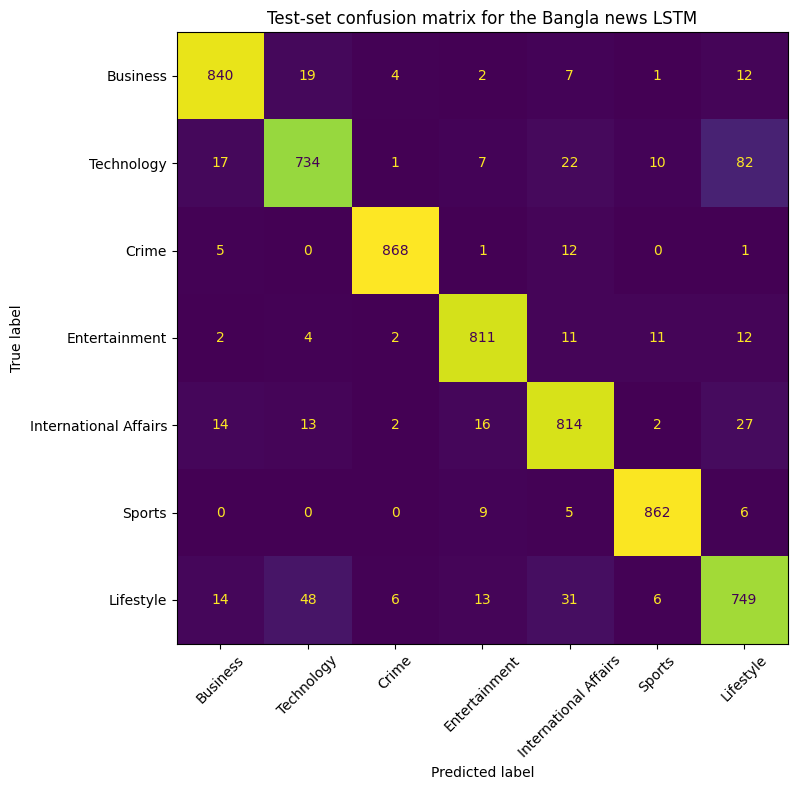

In [20]:
# A confusion matrix shows which categories the model mixes up.
conf_matrix = confusion_matrix(test_true, test_predicted, labels=list(range(len(CATEGORIES))))

fig, ax = plt.subplots(figsize=(10, 8))
display = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=CATEGORIES)
display.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Test-set confusion matrix for the Bangla news LSTM")
plt.tight_layout()
plt.show()

**Interpretation:** Correct predictions appear on the main diagonal. Larger numbers away from the diagonal show pairs of categories that the model confuses. Use the matrix and classification report to identify categories needing more attention.

## 23. Inspect examples the model got wrong

In [21]:
# Match the predictions with the original test articles
error_df = test_df.copy().reset_index(drop=True)
error_df["true_label"] = test_true
error_df["predicted_label"] = test_predicted
error_df["true_category"] = error_df["true_label"].map(LABEL_NAMES)
error_df["predicted_category"] = error_df["predicted_label"].map(LABEL_NAMES)

wrong_predictions = error_df[error_df["true_label"] != error_df["predicted_label"]]
print("Incorrect test predictions:", len(wrong_predictions), "out of", len(error_df))

# Display up to five wrong predictions for manual inspection
for _, row in wrong_predictions.head(5).iterrows():
    print("True category:     ", row["true_category"])
    print("Predicted category:", row["predicted_category"])
    print("Article preview:   ", row["text"][:400].replace("\n", " "))
    print("-" * 70)

Incorrect test predictions: 457 out of 6135
True category:      Business
Predicted category: Lifestyle
Article preview:    শ্রমিকেরা শোষিত হচ্ছেন নানাভাবে। দেশের শ্রমিকসংগঠনের নেতারা সভা-সমাবেশে প্রায়ই এ কথা বলেন, বিক্ষোভ করেন ও প্রতিকার চান। তবে এবারের ঘটনা ভিন্ন। পোশাকশ্রমিকেরা নিজেরাই নিজেদের করুণ আকুতির কথা হাতে লিখে পোশাকের গায়ে লেবেল হিসেবে জুড়ে দিয়েছেন।এ রকম তিনটি লেবেল আয়ারল্যান্ডভিত্তিক খুচরা বিক্রেতাপ্রতিষ্ঠান প্রাইমার্কের পোশাকে খঁুজে পাওয়া গেছে। আর তা পেয়েছেন যুক্তরাজ্যের ভিন্ন তিন নারী ক্রেতা। লেবেল
----------------------------------------------------------------------
True category:      Business
Predicted category: Technology
Article preview:    ৫ অক্টোবর যশোরের শেখ হাসিনা সফটওয়্যার টেকনোলজি পার্কে বসছে চাকরি মেলা। এতে একই দিনে চাকরিপ্রত্যাশীদের জীবনবৃত্তান্তসহ আবেদন ও পরীক্ষা গ্রহণ এবং তাৎক্ষণিকভাবে চাকরির নিয়োগপত্র দেওয়ার লক্ষ্য নিয়ে চাকরি প্রদানকারী দেশি-বিদেশি ৪০টি কোম্পানি অংশ নিচ্ছে। খুলনা বিভাগের বিভিন্ন কলেজ ও বিশ্ববিদ্যালয়ের অন্তত পাঁচ হাজার শিক্ষার্থী এ ম

## 24. Try the model on one new article


In [22]:
# Paste a REAL Bangla news article (not only a headline) between the quotation marks.
# The model was trained on full article text, so use the same input type for a meaningful test.
new_article = ""

def predict_category(text):
    if not isinstance(text, str) or text.strip() == "":
        raise ValueError("Please provide a non-empty Bangla news article.")

    encoded_ids, sequence_length = encode_text_with_length(text)
    input_ids = torch.tensor([encoded_ids], dtype=torch.long).to(device)
    input_lengths = torch.tensor([sequence_length], dtype=torch.long).to(device)

    model.eval()
    with torch.no_grad():
        scores = model(input_ids, input_lengths)
        probabilities = torch.softmax(scores, dim=1)[0]
        confidence, predicted_id = torch.max(probabilities, dim=0)

    return {
        "category": LABEL_NAMES[int(predicted_id.item())],
        "confidence": round(float(confidence.item()), 4),
        "note": "Confidence is the model's score, not a guarantee that the prediction is correct."
    }

if new_article.strip():
    print(predict_category(new_article))
else:
    print("Paste a full Bangla news article into new_article, then run this cell again.")


Paste a full Bangla news article into new_article, then run this cell again.


## 25. Save the model files for your teammate

In [23]:
# 25. Save the LSTM experiment files (kept separate from the Logistic Regression model)
SAVE_DIR = "artifacts_lstm_experiment"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save the trained model weights (the BEST epoch's weights, loaded at the end of Section 19)
torch.save(model.state_dict(), f"{SAVE_DIR}/bangla_news_lstm_state_dict.pt")

# 2. Save the word-to-number vocabulary
with open(f"{SAVE_DIR}/vocab.json", "w", encoding="utf-8") as file:
    json.dump(vocab, file, ensure_ascii=False)

# 3. Save the model settings and category names
model_config = {
    "vocab_size": len(vocab),
    "max_len": MAX_LEN,
    "padding_side": "right",
    "uses_packed_sequences": True,
    "embedding_size": EMBEDDING_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "number_of_classes": len(CATEGORIES),
    "pad_id": PAD_ID,
    "unknown_id": UNKNOWN_ID,
    "improved": IMPROVED,
    "bidirectional": IMPROVED,
    "best_epoch": best_epoch,
    "label_names": {str(key): value for key, value in LABEL_NAMES.items()}
}
with open(f"{SAVE_DIR}/model_config.json", "w", encoding="utf-8") as file:
    json.dump(model_config, file, ensure_ascii=False, indent=4)

# 4. Save the evaluation metrics from this run
metrics = {
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_weighted_f1": test_weighted_f1,
    "best_validation_accuracy": best_val_acc
}
with open(f"{SAVE_DIR}/test_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print("Saved files in", SAVE_DIR + "/")
for name in sorted(os.listdir(SAVE_DIR)):
    print("-", name)

Saved files in artifacts_lstm_experiment/
- bangla_news_lstm_state_dict.pt
- model_config.json
- test_metrics.json
- vocab.json


## 26. Prepare the fresh-data test (at least 30 new articles)

The assignment requires at least **30 articles that are not in the original dataset**. Collect recent or otherwise independent articles, record the source URL and publication date (prefer `YYYY-MM-DD`), and assign labels consistently. Use full article text because that is what this model was trained on. Do not copy rows from the training, validation, or test split. The following cell creates a blank template only if the file does not already exist.


In [24]:
# 1. Make the folder
os.makedirs("fresh", exist_ok=True)

# 2. Create a template if it does not already exist
fresh_file = "fresh/fresh_samples.csv"
fresh_columns = ["text", "true_label", "source_url", "publication_date"]

if not os.path.exists(fresh_file):
    empty_fresh_data = pd.DataFrame(columns=fresh_columns)
    empty_fresh_data.to_csv(fresh_file, index=False, encoding="utf-8-sig")
    print("Created blank template:", fresh_file)
else:
    print("Template already exists; it was not overwritten:", fresh_file)

print("\nUse these exact category labels in the true_label column:")
for category in CATEGORIES:
    print("-", category)

print("\nOpen fresh/fresh_samples.csv and add at least 30 new articles.")

Created blank template: fresh/fresh_samples.csv

Use these exact category labels in the true_label column:
- Business
- Technology
- Crime
- Entertainment
- International Affairs
- Sports
- Lifestyle

Open fresh/fresh_samples.csv and add at least 30 new articles.


## 27. Evaluate the fresh articles when you have collected them

This cell checks the sample count, required columns, labels, source URL/date format, duplicates inside the fresh CSV, and overlap with the original dataset after text normalization. It only reports fresh-data metrics when at least 30 complete, valid, non-duplicate articles remain. Fresh-data results are intentionally not filled in until you collect real articles.


In [25]:
# 1. Load the fresh articles
fresh_df = pd.read_csv(fresh_file, encoding="utf-8-sig")
print("Rows in fresh CSV before validation:", len(fresh_df))

required_columns = ["text", "true_label", "source_url", "publication_date"]
missing_columns = [column for column in required_columns if column not in fresh_df.columns]

if missing_columns:
    print("Missing columns:", missing_columns)
    print("Add the missing columns and run this cell again.")
else:
    # 2. Keep only complete rows; do not silently evaluate missing labels or metadata
    fresh_df = fresh_df.copy()
    for column in required_columns:
        fresh_df[column] = fresh_df[column].fillna("").astype(str).str.strip()

    before_complete_check = len(fresh_df)
    complete_mask = (fresh_df[required_columns] != "").all(axis=1)
    fresh_df = fresh_df.loc[complete_mask].copy()
    removed_incomplete = before_complete_check - len(fresh_df)
    print("Rows removed for missing/blank required fields:", removed_incomplete)
    print("Complete rows remaining:", len(fresh_df))

    # 3. Check category spelling
    valid_labels = set(CATEGORIES)
    invalid_labels = sorted(set(fresh_df["true_label"]) - valid_labels)

    # 4. Validate source URL and publication date metadata
    valid_url_mask = fresh_df["source_url"].str.match(r"^https?://\S+$", case=False, na=False)
    invalid_url_count = int((~valid_url_mask).sum())
    parsed_dates = pd.to_datetime(fresh_df["publication_date"], errors="coerce")
    invalid_date_count = int(parsed_dates.isna().sum())

    # 5. Check duplicates within the fresh CSV after normalization
    normalized_fresh_texts = fresh_df["text"].map(normalize_text_for_match)
    duplicate_fresh_count = int(normalized_fresh_texts.duplicated(keep=False).sum())

    # 6. Check overlap with every original dataset split after normalization
    original_texts_normalized = set()
    for split_name in ["train", "validation", "test"]:
        original_texts_normalized.update(
            normalize_text_for_match(text) for text in ds[split_name]["text"] if str(text).strip()
        )
    overlapping_count = int(normalized_fresh_texts.isin(original_texts_normalized).sum())

    print("Invalid category labels:", invalid_labels)
    print("Invalid source URLs (must start with http:// or https://):", invalid_url_count)
    print("Invalid publication dates:", invalid_date_count)
    print("Duplicate fresh rows (all members of repeated groups counted):", duplicate_fresh_count)
    print("Normalized overlaps with the original dataset:", overlapping_count)

    # 7. Do not report metrics until every validation condition passes
    validation_problems = []
    if len(fresh_df) < 30:
        validation_problems.append("fewer than 30 complete articles remain")
    if invalid_labels:
        validation_problems.append("one or more true_label values do not match the seven category names")
    if invalid_url_count > 0:
        validation_problems.append("one or more source URLs are invalid or missing http(s)")
    if invalid_date_count > 0:
        validation_problems.append("one or more publication dates could not be parsed")
    if duplicate_fresh_count > 0:
        validation_problems.append("duplicate articles exist inside the fresh CSV")
    if overlapping_count > 0:
        validation_problems.append("one or more articles overlap the original dataset")

    if validation_problems:
        print("\nFresh-data evaluation is NOT ready:")
        for problem in validation_problems:
            print("-", problem)
        print("Correct these issues, then run this cell again.")
    else:
        # 8. Convert true category names into numerical labels expected by PyTorch
        category_to_label = {name: number for number, name in LABEL_NAMES.items()}
        fresh_true = fresh_df["true_label"].map(category_to_label).tolist()

        # 9. Predict each fresh article using the same tokenizer and sequence-length logic
        fresh_predicted = []
        for article_text in fresh_df["text"]:
            prediction = predict_category(article_text)
            fresh_predicted.append(category_to_label[prediction["category"]])

        # 10. Calculate fresh-data metrics
        fresh_accuracy = accuracy_score(fresh_true, fresh_predicted)
        fresh_macro_f1 = f1_score(fresh_true, fresh_predicted, average="macro", zero_division=0)
        print(f"\nFresh-data accuracy: {fresh_accuracy:.4f}")
        print(f"Fresh-data macro F1: {fresh_macro_f1:.4f}")
        print("\nFresh-data classification report:")
        print(classification_report(
            fresh_true,
            fresh_predicted,
            labels=list(range(len(CATEGORIES))),
            target_names=CATEGORIES,
            zero_division=0
        ))

        # 11. Save all fresh-data predictions for the project report
        fresh_results = fresh_df.copy()
        fresh_results["predicted_label"] = [LABEL_NAMES[number] for number in fresh_predicted]
        fresh_results["correct"] = fresh_results["true_label"] == fresh_results["predicted_label"]
        fresh_results.to_csv("fresh/fresh_predictions.csv", index=False, encoding="utf-8-sig")
        print("Saved: fresh/fresh_predictions.csv")

        print("\nCompare fresh-data metrics with the saved test metrics.")
        print("Explain differences; fresh-data performance may not match the original test score.")


Rows in fresh CSV before validation: 0
Rows removed for missing/blank required fields: 0
Complete rows remaining: 0
Invalid category labels: []
Invalid source URLs (must start with http:// or https://): 0
Invalid publication dates: 0
Duplicate fresh rows (all members of repeated groups counted): 0
Normalized overlaps with the original dataset: 0

Fresh-data evaluation is NOT ready:
- fewer than 30 complete articles remain
Correct these issues, then run this cell again.


## 28. Final checklist

- [ ] Run all cells from top to bottom in a fresh Colab runtime.
- [ ] Confirm normalized train/validation/test overlap checks all report `True`.
- [ ] Explain the shared tokenizer, training-only vocabulary, padding IDs, and sequence lengths.
- [ ] Explain why right-padding is combined with `pack_padded_sequence` for the LSTM.
- [ ] Review the training/validation curves and final test metrics from this updated run.
- [ ] Collect and correctly label at least 30 genuinely new **full articles**.
- [ ] Fix all warnings from the fresh-data validation cell before reporting fresh-data metrics.
- [ ] Save the updated model artifacts and the fresh prediction CSV.
- [ ] Review the Django integration separately; this notebook alone does not verify the web app, database, authentication, or URLs.
- [ ] Disclose AI assistance according to the course instructions and keep the required usage log.



- [ ] Run all cells from top to bottom and save the notebook with the outputs.
- [ ] Read and understand the cleaning, the word-to-number step, the LSTM model and the training loop.
- [ ] Write down the test results from Section 21 (accuracy and macro F1).
- [ ] Discuss one pair of categories the model confuses (Technology and Lifestyle) and show examples of errors (Sections 22 and 23).
- [ ] Collect at least 30 new articles and run the fresh-data test (Sections 26 and 27).
- [ ] Give the Django teammate the files in `artifacts_lstm_experiment/` and explain how they were made. The teammate needs PyTorch and rebuilds the model from `model_config.json`.
- [ ] Tell the teammate which AI tools helped with this notebook, for the AI usage log.

## Limitations

- The model is a word-level LSTM trained from scratch. It uses only Bangla words, and it cuts long articles to a fixed length.
- It was trained and tested on full articles. Headlines were not tested and may work worse.
- Technology and Lifestyle overlap, and some dataset labels look wrong.
- The training articles seem to be from about 2012 to 2018, so recent news may behave differently.
- The dataset card does not say who owns the rights to the news articles.